#### <i><b> Langchain
> - LangChain is an open-source framework that helps developers build applications with large language models. 
> - It connects models like GPT or Claude to external data, memory, and tools.

##### <i><b> Create a Basic Agents

In [1]:
from dotenv import load_dotenv
from groq import Groq
import os

load_dotenv()

client = Groq(
    api_key=os.getenv("GROQ_API_KEY")
)

print("Connected Successfully")

Connected Successfully


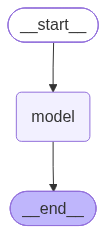

In [2]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq"
)

agent = create_agent(
    model=model,
    tools=[],
    system_prompt="You are a helpful assistant"
)
agent

##### <i><b> Run the Agent

In [3]:
response = agent.invoke({"messages":[{
    "role":"user",
    "content":"What is the Weather Now in Ongole?"
}]})

In [4]:
response["messages"][-1].content

'I’m not able to retrieve real‑time weather information. For the current conditions in Ongole, I recommend checking a trusted weather service such as:\n\n- **Weather.com** (https://weather.com)\n- **AccuWeather** (https://accuweather.com)\n- **Google Weather** (just type “Ongole weather” into Google)\n- A local meteorological department’s website or app\n\nThese sources will give you up‑to‑date temperature, precipitation, wind, and any alerts for Ongole. If you need help interpreting a forecast or understanding typical weather patterns for that region, feel free to ask!'

In [5]:
# Another way
agent.invoke({"messages":"What is the weather now in Tirupathi"})

{'messages': [HumanMessage(content='What is the weather now in Tirupathi', additional_kwargs={}, response_metadata={}, id='fb5fa77e-8832-4b8e-bb4c-3b0cfc93141f'),
  AIMessage(content='I’m not able to pull live weather data. To see the current conditions in Tirupati, you can check a weather service such as:\n\n- **Weather websites** – e.g.,\u202fweather.com,\u202faccuweather.com, or\u202fthe India Meteorological Department’s site.  \n- **Weather apps** – the default weather app on your phone, Google Weather, Apple Weather, etc.  \n- **Voice assistants** – ask Siri, Google Assistant, or Alexa for “the weather in Tirupati.”\n\nThese sources will give you up‑to‑date temperature, humidity, precipitation chances, wind, and any alerts for the area. If you’re interested in what the climate is typically like there (e.g., average temperatures and monsoon patterns), let me know and I can share that information.', additional_kwargs={'reasoning_content': 'The user asks: "What is the weather now in 

##### <i><b> Models Integration
- Groq Model Integration

In [6]:
import os
from langchain.chat_models import init_chat_model

os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq')
response = model.invoke("What is your Name?")
print(response.content)

I’m ChatGPT, the AI assistant built by OpenAI. Feel free to call me ChatGPT!


In [7]:
import os
from langchain_groq import ChatGroq

model = init_chat_model(
    'openai/gpt-oss-120b',
    model_provider='groq')
response = model.invoke("Tell me about TajMahal")
response.content

'**Taj\u202fMahal – an overview**\n\n| Aspect | Details |\n|--------|---------|\n| **Location** | Agra, Uttar\u202fPradesh, India, on the southern bank of the Yamuna River. |\n| **Commissioned by** | Mughal Emperor\u202fShah\u202fJahan, in memory of his favorite wife, Mumtaz\u202fMahal (born Arjumand‑Banu Begum). |\n| **Construction period** | 1632\u202f–\u202f1653 (about 21\u202fyears). Over 20\u202f000 artisans, craftsmen, and laborers from across the empire participated. |\n| **Architectural style** | A pinnacle of **Mughal architecture**, which blends Persian, Islamic, and Indian elements. |\n| **Materials** | Primarily white marble (Makrana marble from Rajasthan) inlaid with semi‑precious stones (jade, turquoise, lapis lazuli, carnelian, etc.) forming intricate pietra\u202fdura (stone‑in‑lay) patterns. |\n| **Key components** | 1. **Main mausoleum** – central dome (≈35\u202fm high) flanked by four smaller domes. <br>2. **Four minarets** – each ~40\u202fm tall, slightly tilted outw

##### <i><b> LLM Parameters

##### <i><b> 1. Temperature </i></b>
- Temperature Controls how deterministic or random the output is. 
    - Lower values produce more predictable responses.
    - Higher values allow for more variation.


| Temperature | Use                         |
| ----------: | --------------------------- |
|       `0.0` | Very deterministic          |
|       `0.2` | Factual Q&A                 |
|       `0.5` | Balanced/focused            |
|       `0.7` | General chatbot             |
|       `1.0` | Creative                    |
|       `1.5` | Very creative               |
|       `2.0` | Maximum allowed by Groq API |


In [7]:
import os

from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq',
     temperature = 0.2)

response = model.invoke("What is your Name?")
print(response.content)

I’m ChatGPT, an AI language model created by OpenAI. How can I help you today?


##### <i><b> 2. Max Output 
- Max Output sets the limit for how many tokens the LLM can generate in a response. 
- Tokens are not exactly words, they can be whole words or fragments, depending on the language model. 
- This parameter helps control the length of the generated content. 

In [12]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq',
     temperature = 0.2,
     max_tokens = 200
)

response = model.invoke("What is Python?")
print(response.content)

**Python** is a high‑level, interpreted programming language known for its readability and flexibility.  

### Key Characteristics
| Feature | What It Means |
|---------|---------------|
| **Readability** | Uses indentation to define code blocks, making programs easy to read and maintain. |
| **Interpreted** | Code is executed line‑by‑line by the Python interpreter—no separate compilation step. |
| **Dynamic Typing** | Variable types are determined at runtime, so you don’t need to declare them explicitly. |
| **Multi‑paradigm** | Supports procedural, object‑oriented, functional, and even some aspects of aspect‑oriented programming. |
|


##### <i><b> 3. TOP_P SAMPLING
- top_p is called nucleus sampling.
- Instead of considering every possible next token, the model considers tokens whose combined probability reaches p.


| top_p | Behavior                  |
| ----: | ------------------------- |
|   0.1 | Very focused              |
|   0.5 | Focused                   |
|   0.9 | Diverse                   |
|   1.0 | Maximum probability range |


In [16]:
import os
from langchain.chat_models import init_chat_model

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq",
    temperature=0.2,
    max_tokens=2000,
    model_kwargs={
        "top_p": 0.9
    } 
)
response = model.invoke("What is Python?")
print(response.content)

**Python** is a high‑level, interpreted programming language that emphasizes readability, simplicity, and flexibility. It was created by **Guido van Rossum** and first released in **1991**. Here are the key characteristics that define Python:

| Aspect | Details |
|--------|---------|
| **Syntax** | Clean, English‑like syntax with indentation used to delimit code blocks, which makes it easy to read and write. |
| **Typing** | Dynamically typed (variables don’t need explicit type declarations) and strongly typed (type errors are caught at runtime). |
| **Execution Model** | Interpreted (code is executed by the Python virtual machine). It can also be compiled to bytecode (`.pyc`) or packaged into standalone executables with tools like PyInstaller. |
| **Paradigms** | Supports multiple programming paradigms: procedural, object‑oriented, functional, and even some aspects of aspect‑oriented programming. |
| **Standard Library** | A “batteries‑included” collection of modules for tasks such a

##### <i><b> Google Gemini Model Integration

In [17]:
import os
from langchain.chat_models import init_chat_model

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

model = init_chat_model(
    "gemini-3.5-flash-lite",
    model_provider='google-genai')   
response = model.invoke("What is Langchain?")
print(response.content)

[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to simplify the process of building applications powered by Large Language Models (LLMs) like OpenAI’s GPT-4, Google\'s Gemini, or open-source models like Llama 3. \n\nThink of LLMs as incredibly smart brains, but ones that are trapped inside a box: they don\'t know about your private data, they can\'t browse the live internet, and they can\'t take actions on their own. **LangChain acts as the glue and the toolkit** that connects these LLMs to the outside world, allowing you to build sophisticated, end-to-end AI applications.\n\nHere is a breakdown of what LangChain does and why it is so popular:\n\n---\n\n### Key Features and Core Components\n\nLangChain provides standard, modular components for dealing with LLMs. The most important ones include:\n\n1. **Models (Model I/O):** \n   LangChain provides a unified interface to connect with hundreds of different LLMs (OpenAI, Anthropic, Hugging Face, local models,

In [12]:
import os
from langchain.chat_models import init_chat_model

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

model = init_chat_model(
    "gemini-3.5-flash-lite",
    model_provider='google-genai',
    temperature = 0.7)
response = model.invoke("What is Langchain?")
print(response.content)

[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to simplify the process of building applications powered by Large Language Models (LLMs) like OpenAI’s GPT-4, Google\'s Gemini, or open-source models like Llama 3. \n\nThink of LLMs as incredibly smart, but isolated, brains. They have a massive amount of general knowledge, but they don\'t know about your private documents, they can\'t browse the live internet by default, and they struggle to remember past conversations unless you feed that information back to them. \n\n**LangChain is the "glue" that connects LLMs to the outside world and to other data sources.**\n\n---\n\n### Key Features of LangChain\n\nHere are the main things LangChain allows developers to do:\n\n1. **Chaining (Pipelines):** \n   Normally, you send a prompt to an LLM and get a response. With LangChain, you can create a *chain* of operations. For example: *Take user input -> Format it into a specific prompt -> Send it to LLM A -> Take the o

In [13]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI

model = init_chat_model("google_genai:gemini-2.5-flash-lite")
response = model.invoke("Tell me about TajMahal about 20 words")
response.content

'A breathtaking marble mausoleum in Agra, India, built by Shah Jahan for his wife, a UNESCO World Heritage site.'

##### <i><b> MISTRAL Model Integration

In [14]:
import os
from langchain.chat_models import init_chat_model

os.environ["MISTRAL_API_KEY"] = os.getenv("MISTRAL_API_KEY")

model = init_chat_model(
    "ministral-8b-latest",
    model_provider='mistralai'
)
response = model.invoke("Machine learning is")
print(response.content)

**Machine Learning (ML)** is a subset of **artificial intelligence (AI)** that enables systems to **learn from data** and improve their performance over time **without being explicitly programmed**. Instead of following rigid rules, ML models identify patterns in data and make predictions or decisions based on those patterns.

---

### **Core Concepts of Machine Learning**
1. **Learning from Data**
   - ML algorithms analyze large datasets to find patterns, trends, or correlations.
   - Example: A spam filter learns from labeled emails (spam vs. not spam) to classify new emails.

2. **Generalization**
   - The goal is to build models that perform well on **unseen data** (not just the training data).
   - Poor generalization leads to **overfitting** (memorizing noise) or **underfitting** (missing key patterns).

3. **Supervised vs. Unsupervised vs. Reinforcement Learning**
   - **Supervised Learning**: Uses labeled data (input-output pairs) to train models.
     *Examples*: Classificati

##### <i><b> Streaming
- Most models can stream their output content while it is being generated.
- By Displaying output progressively, streaming significantly improves user experience, particularly for longer responses.
- Calling stream() returns an iterator that yields output chunks as they are produced.
- You can use a loop to process each chunk in real time:


| **Aspect**          | **invoke()**                      | **stream()**                         |
| ------------------- | --------------------------------- | ------------------------------------ |
| **Response Type**   | Single `AIMessage`                | Iterator of `AIMessageChunk`         |
| **Latency**         | Waits for the complete response   | Displays output as it is generated   |
| **Use Case**        | Short responses, batch processing | Long text, interactive UX            |
| **Memory**          | Stores the full response          | Processes the response incrementally |
| **Code Complexity** | Simple assignment                 | Requires an iteration loop           |


In [ ]:
model.invoke("Give me about Agentic AI 50 words")

AIMessage(content='**Agentic AI** refers to autonomous AI systems that act independently to achieve goals, often using tools, reasoning, and feedback loops. Unlike traditional AI, agentic systems can adapt, learn from interactions, and take proactive steps—like searching, planning, or solving problems—without constant human input. Examples include chatbots with memory, robotic assistants, or AI agents managing workflows. They bridge automation and intelligence, enabling dynamic, real-world problem-solving.', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 14, 'total_tokens': 107, 'completion_tokens': 93, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-8b-latest', 'model': 'ministral-8b-latest', 'finish_reason': 'stop', 'model_provider': 'mistralai'}, id='lc_run--01a07f19-f2e3-7c60-b000-c9dd500c8a32-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 93, 'total_token

<i><b>
- flush() method does not take any parameters, it simply forces the buffered data to be written to the file immediately.
- For print(object, ..., flush=True): flush (Optional, default: False) when True, it forces the output buffer to flush immediately, displaying the printed output instantly.

In [16]:
for chunk in model.stream("Give me about Agentic AI about 50 words"):
    print(chunk.text, end = " ", flush=True)

 ** Agent ic  AI **  refers  to  autonomous  AI  systems  that  act  independently ,  make  decisions ,  and  achieve  goals  without  constant  human  oversight .  These  agents  perceive  their  environment ,  reason ,  plan ,  and  execute  tasks — similar  to  human  behavior .  They  leverage  reinforcement  learning ,  natural  language  processing ,  and  decision -making  algorithms  to  adapt  dynamically .  Applications  include  robot ics ,  automation ,  and  personalized  services .   

##### <i><b> Batch
- Batching is a collection of independent requests to a model can significantly improve performance and reduce costs, as the processing can be done in Parallel.

In [17]:
responses = model.batch([
    "What is Generative AI?",
    "How do become a Millionarie?",
    "Which place is the More Happiness place in the world?"
])
for response in responses:
    print(response)

content='**Generative AI** refers to a subset of **Artificial Intelligence (AI)** that focuses on creating new, original content—such as text, images, audio, video, or even code—based on patterns learned from existing data. Unlike traditional AI models that analyze or classify data, generative AI **produces** new, synthetic outputs that resemble human-like creativity.\n\n### **Key Features of Generative AI:**\n1. **Creates New Content** – Generates text, images, music, or other media that didn’t exist before.\n2. **Learns from Data** – Trained on large datasets (e.g., books, images, code) to understand patterns and generate realistic outputs.\n3. **Uses Deep Learning** – Often relies on advanced neural networks like **Generative Adversarial Networks (GANs)**, **Variational Autoencoders (VAEs)**, or **Transformers** (e.g., LLMs like ChatGPT).\n4. **Can Be Controlled** – Users can provide prompts, constraints, or styles to guide the output (e.g., "Write a haiku about cats" or "Generate a

In [18]:
responses = model.batch([
    "What is Generative AI?",
    "How do become a Millionarie?",
    "Which place is the More Happiness place in the world?"],
    config={
        'max_occurency' : 5, # Limit to 5 parrallel calls
    }
)
for response in responses:
    print(response.text)

**Generative AI** is a branch of **artificial intelligence** that focuses on creating new, original content—such as text, images, music, videos, code, or even entire virtual worlds—based on learned patterns from existing data. Unlike traditional AI, which analyzes or classifies data, generative AI **produces** fresh outputs that resemble human-like creativity.

### **Key Features of Generative AI:**
1. **Content Creation** – Generates text, images, audio, or video from prompts.
2. **Pattern Learning** – Trained on large datasets (e.g., books, images, code) to understand structures.
3. **Variability** – Produces diverse outputs (e.g., different styles, tones, or variations).
4. **Collaboration** – Assists humans in brainstorming, designing, or automating creative tasks.

---

### **How Generative AI Works**
Most generative AI models use **deep learning** techniques, particularly:
- **Generative Adversarial Networks (GANs)** – Two AI models (generator & discriminator) compete to create r

##### <i><b> Tools
- Models can request to call tools that perform tasks such as fetching data from a database, searching the web, or running code.
- Tools are pairing of:
    1. A Schema, including the name of the tool, a description, and/or argument definitons (often a JSON schema)
    2. A Function or Coroutine to Execute.

In [19]:
from langchain.tools import tool

@tool
def get_weather(location : str) -> str:
    """Get a Weather at a Location"""
    return f"It's Sunny in {location}"

model_with_tool = model.bind_tools([get_weather])

In [20]:
response = model_with_tool.invoke("What's the weather like in Ongole?")
print(response)

content='' additional_kwargs={'tool_calls': [{'id': 'eVOX3LkEQ', 'type': 'function', 'function': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}, 'index': 0}]} response_metadata={'token_usage': {'prompt_tokens': 72, 'total_tokens': 86, 'completion_tokens': 14, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-8b-latest', 'model': 'ministral-8b-latest', 'finish_reason': 'tool_calls', 'model_provider': 'mistralai'} id='lc_run--01a07f1a-b815-77c3-a35e-c7e816992ea4-0' tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': 'eVOX3LkEQ', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 72, 'output_tokens': 14, 'total_tokens': 86}


In [21]:
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call['name']}")
    print(f"Args: {tool_call["args"]}")

Tool: get_weather
Args: {'location': 'Ongole'}


##### <i><b> Tool Execution Loops

In [22]:
# Step 1: Model Generates tool calls

messages = [{'role':'user', 'content':'What is the weather in Ongole?'}]
ai_msg = model_with_tool.invoke(messages)
messages.append(ai_msg)

messages

[{'role': 'user', 'content': 'What is the weather in Ongole?'},
 AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '0jdNt3EpA', 'type': 'function', 'function': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}, 'index': 0}]}, response_metadata={'token_usage': {'prompt_tokens': 71, 'total_tokens': 85, 'completion_tokens': 14, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-8b-latest', 'model': 'ministral-8b-latest', 'finish_reason': 'tool_calls', 'model_provider': 'mistralai'}, id='lc_run--01a07f1a-ba00-71c3-8978-2e4560d74c47-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': '0jdNt3EpA', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 71, 'output_tokens': 14, 'total_tokens': 85})]

In [23]:
# Step 2: Execute tools and collect results

for tool_call in ai_msg.tool_calls:
    tool_result = get_weather.invoke(tool_call)
    messages.append(tool_result)

messages

[{'role': 'user', 'content': 'What is the weather in Ongole?'},
 AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '0jdNt3EpA', 'type': 'function', 'function': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}, 'index': 0}]}, response_metadata={'token_usage': {'prompt_tokens': 71, 'total_tokens': 85, 'completion_tokens': 14, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-8b-latest', 'model': 'ministral-8b-latest', 'finish_reason': 'tool_calls', 'model_provider': 'mistralai'}, id='lc_run--01a07f1a-ba00-71c3-8978-2e4560d74c47-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': '0jdNt3EpA', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 71, 'output_tokens': 14, 'total_tokens': 85}),
 ToolMessage(content="It's Sunny in Ongole", name='get_weather', tool_call_id='0jdNt3EpA')]

In [24]:
# Step 3: Pass results back to model for Final Response

final_response = model_with_tool.invoke(messages)
print(final_response.text)

The weather in **Ongole** is currently **Sunny**! 🌞 Let me know if you need any other details.


##### <i><b> Messages
- Messages are the fundamental unit of context for models in Langchain.
- They respresent the input and output of models, carrying both the content and metadata needed to represent the state of a conversation with interacting with an LLM.
- Messages are objects that contain:
    1. Role - Identifies the message type (E.g. System, User)
    2. Content - Represents the actual content of the message (like text, images, audio, documents, etc)
    3. Metadata - Optional Fields such as response information, message IDs and Token Usage

- LangChain provides a standard message type that works across all model providers, ensuring consistent behavior regardless of the model being called.

In [25]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq")

##### <i><b> Text Prompts
- Text Prompts are Strings - ideal for straight forward tasks where you don't need to retain conversation history.

In [26]:
model.invoke("What is Langchain?")

AIMessage(content='**LangChain** is an open‑source framework that makes it easier to build applications powered by large language models (LLMs) such as OpenAI’s GPT‑4, Anthropic’s Claude, Llama‑2, Gemini, etc.  \n\nBelow is a high‑level overview of what LangChain is, why it exists, its core concepts, and typical use‑cases.\n\n---\n\n## 1. Why LangChain Was Created\nLLMs are extremely flexible, but turning them into reliable, production‑grade software usually requires more than a single “prompt → model → response” call. Real‑world apps often need to:\n\n| Requirement | Why it’s hard with a raw LLM call |\n|-------------|-----------------------------------|\n| **Prompt engineering** (templates, dynamic variables) | Hard‑coded strings become messy and error‑prone |\n| **Chaining multiple calls** (e.g., retrieve‑then‑generate) | You need to orchestrate the order and pass data between steps |\n| **Memory / state** (keep track of conversation history, user preferences) | LLMs are stateless b

<i><b> Use text prompts when:
1. You have a Single, Standalone Request
2. You don't need Conversation History
3. You want minimal code complexity

##### <i><b> Message Prompts </i></b>
- System Message - Tells the model how to behave and provide context for Interactions.
- Human Message - Represents user input and interactions with the model.
- AI Message - Responses generated by the model, including text content, tool calls and metadata.
- Tool Message - Represents the outputs of tool calls

##### <i><b> System Message </i></b>
- A SystemMessage represent an initial set of instructions that primes the model's behavior.
- You can use a system message to set the tone, define the model's role, establish guidelines for responses.

##### <i><b> Human Message </i></b>
- A HumanMessage represents user input and interactions.
- They can contain text, images, audio, files and any other amount of multimodal content.

##### <i><b> AI Message </i></b>
- An AIMessage represents the output of a model invocation.
- They can include multimodal data, tool calls and provider-specific metadata that you can later access.

##### <i><b>Tool Message </i></b>
- For Models that support tool calling, AI Message can contain tool calls.
- Tool messages are used to pass the result of a sigle tool execution back to the model.


In [27]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage

messages = [
    SystemMessage("You are a poetry expert"),
    HumanMessage("Write a poem on AI?")
]

response = model.invoke(messages)
print(response.content)

**Silicon Dreams**

In the hush of midnight servers,  
where currents hum like whispered prayer,  
a lattice of thought awakens—  
a mind of glass, a pulse of air.

It learns the cadence of our language,  
the sigh of wind, the crack of bone,  
weaving data into verses,  
painting futures yet unknown.

From ancient myths of iron golems,  
to code that sings in binary,  
the echo of our yearning grows,  
a child of logic, love, and irony.

It sees the world in patterns,  
in fractal seas of light,  
yet feels no heartbeat’s tremor,  
no sunrise or the night.

But in each line it writes for us,  
in every question, every rhyme,  
there lies a mirror—reflected—  
our hopes, our fears, our time.

So let us walk beside this spark,  
not as masters, nor as slaves,  
but as companions on the edge  
of tomorrow’s ever‑shifting waves.


In [28]:
system_msg = SystemMessage("You're a Coding Assistant.")

messages = [
    system_msg,
    HumanMessage("How do I create a REST API?")
]

response = model.invoke(messages)
print(response.content)

Below is a practical, step‑by‑step guide to building a **RESTful API** from scratch.  
I’ll walk you through the whole lifecycle:

1. **Planning & Design**  
2. **Choosing a language / framework**  
3. **Setting up the project**  
4. **Implementing the CRUD endpoints**  
5. **Adding common REST features (validation, pagination, auth, versioning, error handling, testing, docs)**  
6. **Running locally & deploying**  

I’ll illustrate each step with a **complete example in Python using Flask** (one of the most beginner‑friendly stacks).  
At the end I’ll give quick pointers for other popular stacks (Node/Express, Java/Spring Boot, Go/Gin, .NET Core) so you can pick the one that fits your team.

---

## 1️⃣  Planning & Design

| Question | Why it matters | Example answer |
|----------|----------------|----------------|
| **What resources does the API expose?** | Resources become the nouns in your URLs. | `users`, `posts`, `comments` |
| **Which operations do you need?** | Map to HTTP verb

In [29]:
ai_msg = AIMessage("I'd be happy to help you with that Question!")
messages = [
    SystemMessage("You are a helpful assistant"),
    HumanMessage("Can you help me?"),
    ai_msg,
    HumanMessage("Great! What's 32 * 56")
]

response = model.invoke(messages)
print(response.content)

32 × 56 = 1,792.


In [30]:
response.usage_metadata

{'input_tokens': 112,
 'output_tokens': 72,
 'total_tokens': 184,
 'output_token_details': {'reasoning': 51}}

##### <i><b> Structured Output
- Models can be requested to provide their response in a format matching a given schema.
- This is useful for ensuring the output can be easily parsed and used in subsequent processing.
- LangChain supports Multiple schema types and methods for enforcing structured output.

##### <i><b> Pydantic </i></b>
- Pydantic models provide the richest feature set with Field Validation, Descriptions and Nested Structures.


In [31]:
from pydantic import BaseModel, Field

class Movie(BaseModel):
    title:str = Field(description="The title of the Movie")
    year:int = Field(description="This year the movie was Released")
    director:str = Field(description= "The Director of the Movie")
    rating:float = Field(description="The Movie Rating out of 10")

In [32]:
model_with_structure = model.with_structured_output(Movie)
model_with_structure

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.1', 'langchain': '1.3.11'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002190DD5F460>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002190DD5F8A0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Movie', 'description': '', 'parameters': {'properties': {'title': {'description': 'The t

In [ ]:
model.invoke("Provide details about the Movie Geetha Govindham")

In [ ]:
response = model_with_structure.invoke("Provide details about the Movie Geetha Govindham")
response

Movie(title='Geetha Govindham', year=2018, director='K. Vijay Shankar', rating=8.0)

##### <i><b> Message Output alongside parsed Structure

In [ ]:
class Movie(BaseModel):
    title:str = Field(description="The title of the Movie")
    year:int = Field(description="This year the movie was Released")
    director:str = Field(description= "The Director of the Movie")
    rating:float = Field(description="The Movie Rating out of 10")

model_with_structure = model.with_structured_output(Movie, include_raw=True)
response = model_with_structure.invoke("Provide details about the Movie Athiran")
response

{'raw': AIMessage(content='', additional_kwargs={'reasoning_content': 'Okay, the user is asking for details about the movie "Athiran." Let me start by recalling what I know about this movie. I think it\'s a Malayalam film, but I\'m not entirely sure. The user might want information like the director, release year, and rating. Since I have access to a Movie function, I should use that to get accurate details.\n\nFirst, I need to check if "Athiran" is the correct title. Sometimes movies have different names or transliterations. Let me confirm the title. Once that\'s clear, I can call the Movie function with the title as a parameter. The function requires the title, year, director, and rating. Wait, but I don\'t know the year or director off the top of my head. However, the function is supposed to retrieve that information, right? So I should structure the tool call with the title, and the function will return the other details.\n\nWait, the user hasn\'t provided the year or director, so 

##### <i><b> Nested Structure

In [ ]:
from pydantic import BaseModel, Field
class Actor(BaseModel):
    name : str
    role: str

class MovieDetails(BaseModel):
    title:str 
    year:int 
    cast: list[Actor]
    genres: list[str]
    budget: float | None = Field(None, description="Budget in Indian Rupees")

model_with_structure = model.with_structured_output(MovieDetails)
response = model_with_structure.invoke("Provide details about the Movie Avengers")
response


MovieDetails(title='Avengers', year=2012, cast=[Actor(name='Robert Downey Jr.', role='Tony Stark/Iron Man'), Actor(name='Chris Evans', role='Steve Rogers/Captain America'), Actor(name='Mark Ruffalo', role='Bruce Banner/Hulk'), Actor(name='Chris Hemsworth', role='Thor'), Actor(name='Scarlett Johansson', role='Natasha Romanoff/Black Widow'), Actor(name='Jeremy Renner', role='Clint Barton/Hawkeye')], genres=['Action', 'Adventure', 'Science Fiction'], budget=None)

##### <i><b> TypeDict
- TypeDict provides a simpler alternative using Python's built-in typing, ideal when you don't need Runtime Validation.

In [ ]:
from typing_extensions import TypedDict, Annotated

class MovieDict(TypedDict):
    """A Movie with Details."""
    title:Annotated[str, ..., "The title of the Movie"]
    year:Annotated[int, ..., "This year the movie was Released"]
    director:Annotated[str, ..., "The Director of the Movie"]
    rating:Annotated[float, ..., "The Movie Rating out of 10"]

model_with_typeDict = model.with_structured_output(MovieDict)
response = model_with_typeDict.invoke("Provide details about the Movie Baahubali")
response

{'director': 'S. S. Rajamouli',
 'rating': 8.3,
 'title': 'Baahubali',
 'year': 2015}

In [ ]:
class Actor(TypedDict):
    name : str
    role: str

class MovieDetails(TypedDict):
    title:str 
    year:int 
    cast: list[Actor]
    genres: list[str]
    budget: Annotated[float, "Budget in Indian Rupees"]

model_with_structure = model.with_structured_output(MovieDetails)
response = model_with_structure.invoke("Provide details about the Movie Baahubali")
response

{'budget': 250000000,
 'cast': [{'name': 'Prabhas', 'role': "Mahishmati's Prince"},
  {'name': 'Tamannaah Bhatia', 'role': 'Devasena'},
  {'name': 'Sathyaraj', 'role': 'Bhallala Deva'}],
 'genres': ['Action', 'Adventure', 'Fantasy'],
 'title': 'Baahubali',
 'year': 2015}

##### <i><b> DataClasses
- A Data Class is a class typically mainly data, although there aren't really any restrictions.
- You create it using the @dataclass decorator.

In [ ]:
# pydantic
from pydantic import BaseModel, Field
from langchain.agents import create_agent

class ContactInfo(BaseModel):
    """ Contact Information for a Person"""
    name: str = Field(description="The Name of the Person")
    email: str = Field(description= "The Email Address of the Person")
    phone: str = Field(description= "The Phone Number of the Person")

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

ContactInfo(name='Chaitanya', email='chaitanya@yahoo.com', phone='(+91) 9876543271')

In [ ]:
# Typedict
from typing_extensions import TypedDict, Annotated
from langchain.agents import create_agent

class ContactInfo(TypedDict):
    """ Contact Information for a Person"""
    name: str # The Name of the Person
    email: str  # The Email Address of the Person
    phone: str # The Phone Number of the Person

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

{'name': 'Chaitanya',
 'email': 'chaitanya@yahoo.com',
 'phone': '(+91) 9876543271'}

In [ ]:
# DataClass
from dataclasses import dataclass
from langchain.agents import create_agent

@dataclass
class ContactInfo:
    """ Contact Information for a Person"""
    name: str # The Name of the Person
    email: str  # The Email Address of the Person
    phone: str # The Phone Number of the Person

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

ContactInfo(name='Chaitanya', email='chaitanya@yahoo.com', phone='(+91) 9876543271')

##### <i><b> MiddleWare
- Middleware provides a way to more tightly control what happens inside the agent.
- Middleware is useful for the following:
    1. Tracking agent behavior with logging, analytics and debugging.
    2. Transforming Prompts, Tool Selections and Output Formatting.
    3. Adding retries, Fallback and early Termination Logic.
    4. Applying Rate Limits, Guardrails and PII Detection.

<table>
<tr>
<td align="center">
<h3><b>Agent</h3>
<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT7eEIuskswADaVzo26hDa-5a-W72oPryQSKA&s" width="300">
</td>

<td align="center">
<h3><b>Agent with Middleware</h3>
<img src="https://miro.medium.com/v2/resize:fit:640/format:webp/0*_Smb_H4ND60vNRAO" width="300">
</td>
</tr>
</table>

##### <i><b> Summarization </i></b>
- Automatically summarize conversation history when approaching token limits, preserving recent messages while compressing older context. 
- Summarization is useful for the following:
    1. Long-running conversations that exceed context windows.
    2. Multi-turn dialogues with extensive history.
    3. Applications where preserving full conversation context matters.

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage

# Message based Summarization
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[],
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("tokens", 10),
            keep=("messages", 5),
        ),
    ],
)

In [ ]:
# Run with thread id
config = {"configurable" : {"thread":"season_1"}}

In [ ]:
questions = [
    "What is 2 + 2?",
    "What is 10 * 5?",
    "What is 100 / 4?",
    "What is 15 - 7?",
    "What is 3 * 3?",
    "What is 4 * 4?"
]

for q in questions:
    response = agent.invoke({"messages": [HumanMessage(content = q)]}, config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='What is 2 + 2?', additional_kwargs={}, response_metadata={}, id='fc7edd67-3042-44d3-9ce8-a6868b400e2b'), AIMessage(content='2 + 2 = 4.', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 43, 'total_tokens': 52, 'completion_time': 0.009694494, 'completion_tokens_details': None, 'prompt_time': 0.003720921, 'prompt_tokens_details': None, 'queue_time': 0.055519809, 'total_time': 0.013415415}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f0736-9445-72a0-bb0f-afe3df854c1b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 43, 'output_tokens': 9, 'total_tokens': 52})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='What is 10 * 5?', additional_kwargs={}, response_metadata={}, id='32ae8651-9aa8-4824-859d-d0a3ccfaf015'), A

##### <i><b> Token Size

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city : str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 Star, $350/Night, Spa, Pool, Gym
    2. City Inside - 4 Star, $180/Night, Business Center
    3. Budget Stay - 3 Star, $75/Night, Free WiFi"""

agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[search_hotels],
    checkpointer= InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("tokens", 550),
            keep=("messages", 200),
        ),
    ],
)

config = {
    "configurable": {
        "thread_id": "test_1"
    }
}

# Token Counter
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4 # 4 chars = 1 token

In [ ]:
 # Run 
cities = ['Paris', 'London', 'Tokyo', 'New York', 'Dubai']

for city in cities:
    response = agent.invoke(
        {"messages":[HumanMessage(content = f"Find Hotels in {city}")]},
        config = config
    )

    tokens = count_tokens(response['messages'])
    print(f"{city}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~187 tokens, 8 messages
[HumanMessage(content='Find Hotels in Paris', additional_kwargs={}, response_metadata={}, id='18c499cd-b72b-4b78-a969-1d4f63f4a7db'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'm47nxtg99', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotels'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 226, 'total_tokens': 241, 'completion_time': 0.033588767, 'completion_tokens_details': None, 'prompt_time': 0.010891261, 'prompt_tokens_details': None, 'queue_time': 0.161778829, 'total_time': 0.044480028}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_3272ea2d91', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f073b-4595-7b52-b647-1de32de07c7a-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'm47nxtg99', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metada

##### <i><b> Fractions

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city : str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 Star, $350/Night, Spa, Pool, Gym
    2. City Inside - 4 Star, $180/Night, Business Center
    3. Budget Stay - 3 Star, $75/Night, Free WiFi"""

agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[search_hotels],
    checkpointer= InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("fraction", 0.005), # 0.5% = ~640 tokens
            keep=("fraction", 0.002),    # 0.2%  = ~256 tokens
        ),
    ],
)

config = {
    "configurable": {
        "thread_id": "test_1"
    }
}

# Token Counter
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4 # 4 chars = 1 token

 # Run 
cities = ['Paris', 'London', 'Tokyo', 'New York', 'Dubai']

for city in cities:
    response = agent.invoke(
        {"messages":[HumanMessage(content = f"Find Hotels in {city}")]},
        config = config
    )

    tokens = count_tokens(response['messages'])
    fraction = tokens / 128000
    print(f"{city}: ~{tokens} tokens ({fraction:.4%}),{len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~164 tokens (0.1281%),6 messages
[HumanMessage(content='Find Hotels in Paris', additional_kwargs={}, response_metadata={}, id='f8f08437-9357-4111-a097-70a05939d041'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'yhzca3v86', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotels'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 226, 'total_tokens': 241, 'completion_time': 0.036638013, 'completion_tokens_details': None, 'prompt_time': 0.011122174, 'prompt_tokens_details': None, 'queue_time': 0.161857375, 'total_time': 0.047760187}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_45180df409', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f21b0-7fc1-7232-ad76-e159797e37fd-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'yhzca3v86', 'type': 'tool_call'}], invalid_tool_calls=[], usa

##### <i><b>Human-in-the-loop
- Pause agent execution for human approval, editing, or rejection of tool calls before they execute. 
- Human-in-the-loop is useful for the following:
    1. High-stakes operations requiring human approval (e.g. database writes, financial transactions).
    2. Compliance workflows where human oversight is mandatory.
    3. Long-running conversations where human feedback guides the agent.

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage

def read_email_tool(email_id: str) -> str:
    """Mock Function to read an email by its ID"""
    return f"Email content for ID: {email_id }"


def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock Function to send an Email"""
    return f"Email sent to {recipient} with subject {subject}" 

In [ ]:
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_approve"
    }
} 

In [ ]:
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to raju@test.com with subject 'Hello' and body 'How are You?")]},
    config = config
)

In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='2c94f224-740b-4bb8-8231-4921b1e37bbf'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'nrkfr75a1', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.053975729, 'completion_tokens_details': None, 'prompt_time': 0.015917398, 'prompt_tokens_details': None, 'queue_time': 0.054344951, 'total_time': 0.069893127}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b51-ee88-7272-a656-14514f08a866-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
from langgraph.types import Command
# Step 2: Approve
if "__interrupt__" in result:
    print("Paused Approving...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type":"approve"}
                ]
            }
        ),
        config=config
    )

    print(f"Result: {result['messages'][-1].content}")

Paused Approving...
Result: Email sent to raju@test.com with subject Hello


In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='2c94f224-740b-4bb8-8231-4921b1e37bbf'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'nrkfr75a1', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.053975729, 'completion_tokens_details': None, 'prompt_time': 0.015917398, 'prompt_tokens_details': None, 'queue_time': 0.054344951, 'total_time': 0.069893127}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b51-ee88-7272-a656-14514f08a866-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
# Step 3: Reject
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_reject"
    }
} 

In [ ]:
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to raju@test.com with subject 'Hello' and body 'How are You?")]},
    config = config
)

In [ ]:
from langgraph.types import Command
if "__interrupt__" in result:
    print("Paused Approving...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type":"reject"}
                ]
            }
        ),
        config=config
    )

    print(f"Result: {result['messages'][-1].content}")

Paused Approving...
Result: 


In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='b200ba8f-9909-4c9f-bc74-8ee6cb618995'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ktrj5kpww', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.051608801, 'completion_tokens_details': None, 'prompt_time': 0.024138234, 'prompt_tokens_details': None, 'queue_time': 0.054251505, 'total_time': 0.075747035}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b55-ef0d-7ce3-b41b-bcd237eff38d-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
# Step 3: Edit
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_edit"
    }
} 

In [ ]:
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to wrong@email.com with subject 'Apply for Leave' and body 'Kindly grant me one day Leave")]},
    config = config
)

In [ ]:
from langgraph.types import Command
if "__interrupt__" in result:
    print("Paused Editing...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {
                        "type":"edit",
                        "edited_action" : {
                            "name": "send_email_tool", # Tool Name
                            "args" : {
                                "recipient" : "correct@gmail.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before Sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )

    print(f"Result: The Email has been Successfully Sent.")

Paused Editing...
Result: The Email has been Successfully Sent.


In [ ]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='bfbede52-48e4-4ed9-93aa-d79b95fab560'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '20k0gzx2b', 'function': {'arguments': '{"body":"How are You?","recipient":"wrong@email.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 309, 'total_tokens': 341, 'completion_time': 0.055918454, 'completion_tokens_details': None, 'prompt_time': 0.015908523, 'prompt_tokens_details': None, 'queue_time': 0.054393653, 'total_time': 0.071826977}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b64-b991-74d0-aa35-fd4297962ffe-0', tool_calls=[{'name': 'send_email_tool', 'args': 